In [1]:
import sys
import os
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path



In [2]:
import kagglehub
from pathlib import Path

# Télécharger le dataset depuis Kaggle
path = kagglehub.dataset_download(
    "paultimothymooney/chest-xray-pneumonia"
)

root_path = Path(path)

print("Dataset téléchargé avec succès.")
print("Chemin du dataset :", root_path)
print("Le chemin existe :", root_path.exists())

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Dataset téléchargé avec succès.
Chemin du dataset : /kaggle/input/chest-xray-pneumonia
Le chemin existe : True


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
extensions = {".jpeg", ".jpg", ".png"}

images = [
    file
    for file in root_path.rglob("*")
    if file.is_file() and file.suffix.lower() in extensions
]

print(f"Nombre total d'images : {len(images)}")

Nombre total d'images : 17568


In [5]:
from collections import defaultdict

# Rechercher le dossier qui contient train, test et val
candidates = [
    directory
    for directory in [root_path, *root_path.rglob("*")]
    if directory.is_dir()
    and all((directory / split).is_dir()
            for split in ["train", "test", "val"])
]

if not candidates:
    raise FileNotFoundError(
        "Impossible de trouver un dossier contenant train, test et val."
    )

dataset_dir = candidates[0]

print("Racine des données :", dataset_dir)

for split in ["train", "test", "val"]:
    split_path = dataset_dir / split
    print(f"\n--- {split.upper()} ---")

    for class_dir in sorted(split_path.iterdir()):
        if class_dir.is_dir():
            count = sum(
                1 for file in class_dir.rglob("*")
                if file.is_file()
                and file.suffix.lower() in extensions
            )
            print(f"{class_dir.name} : {count} images")

Racine des données : /kaggle/input/chest-xray-pneumonia/chest_xray

--- TRAIN ---
NORMAL : 1341 images
PNEUMONIA : 3875 images

--- TEST ---
NORMAL : 234 images
PNEUMONIA : 390 images

--- VAL ---
NORMAL : 8 images
PNEUMONIA : 8 images


Images valides : 11712
Fichiers ignorés : 5856


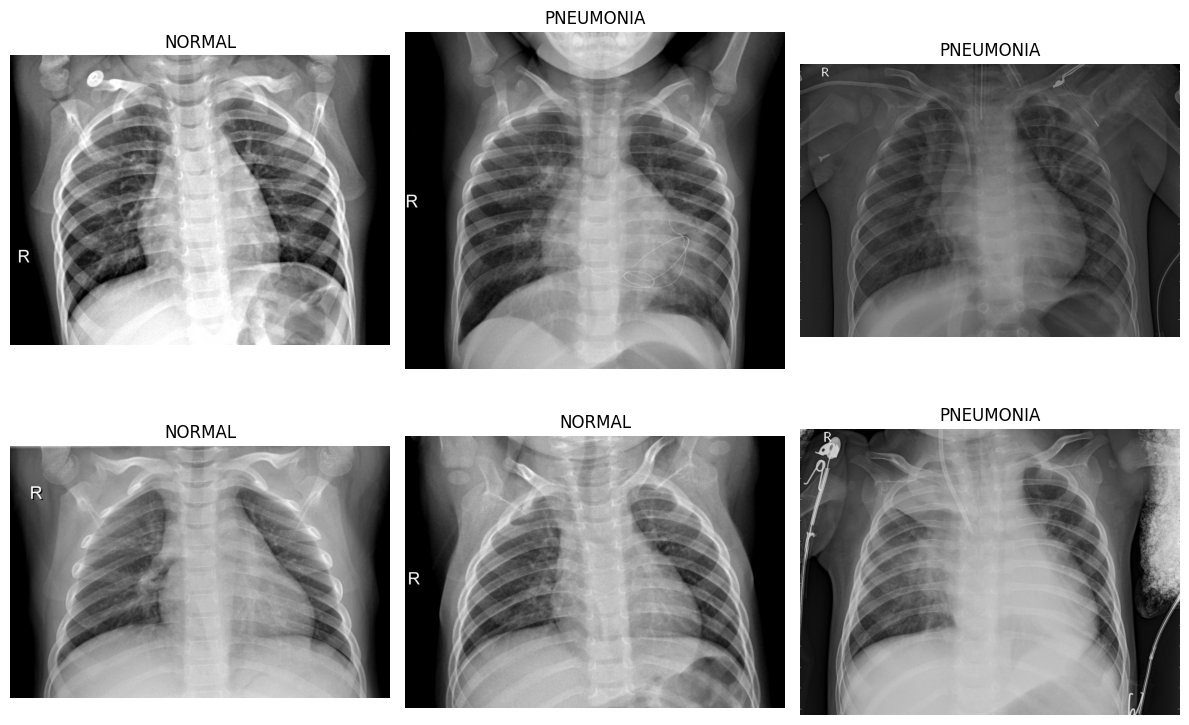

In [6]:

import matplotlib.pyplot as plt
from PIL import Image, UnidentifiedImageError
from pathlib import Path
import random

# Garder uniquement les images valides
valid_images = []

for image_path in images:
    # Ignorer les métadonnées macOS
    if image_path.name.startswith("._"):
        continue

    # Ignorer les fichiers du dossier __MACOSX
    if "__MACOSX" in image_path.parts:
        continue

    try:
        with Image.open(image_path) as img:
            img.verify()
        valid_images.append(image_path)
    except (UnidentifiedImageError, OSError, ValueError):
        continue

print("Images valides :", len(valid_images))
print("Fichiers ignorés :", len(images) - len(valid_images))

# Sélectionner jusqu'à 6 images
random.seed(42)
samples = random.sample(valid_images, min(6, len(valid_images)))

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.flatten()

for ax, image_path in zip(axes, samples):
    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(image_path.parent.name)
    ax.axis("off")

for ax in axes[len(samples):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [7]:

from pathlib import Path
from PIL import Image, UnidentifiedImageError
import pandas as pd

# Trouver la racine contenant train, test et val
candidates = [
    d for d in [root_path, *root_path.rglob("*")]
    if d.is_dir()
    and all((d / split).is_dir()
            for split in ["train", "val", "test"])
]

if not candidates:
    raise FileNotFoundError(
        "Impossible de trouver les dossiers train, val et test."
    )

dataset_dir = candidates[0]
print("Racine du dataset :", dataset_dir)

extensions = {".jpeg", ".jpg", ".png"}
rows = []

for split in ["train", "val", "test"]:
    for class_name in ["NORMAL", "PNEUMONIA"]:
        class_dir = dataset_dir / split / class_name

        if not class_dir.exists():
            print("Dossier manquant :", class_dir)
            continue

        count = 0

        for file_path in class_dir.rglob("*"):
            if not file_path.is_file():
                continue
            if file_path.suffix.lower() not in extensions:
                continue
            if file_path.name.startswith("._"):
                continue
            if "__MACOSX" in file_path.parts:
                continue

            try:
                with Image.open(file_path) as img:
                    img.verify()
                count += 1
            except (UnidentifiedImageError, OSError, ValueError):
                continue

        rows.append({
            "Ensemble": split,
            "Classe": class_name,
            "Nombre_images": count
        })

df_counts = pd.DataFrame(rows)

display(
    df_counts.pivot(
        index="Ensemble",
        columns="Classe",
        values="Nombre_images"
    ).fillna(0).astype(int)
)

print("\nTotal d'images valides :", df_counts["Nombre_images"].sum())


Racine du dataset : /kaggle/input/chest-xray-pneumonia/chest_xray


Classe,NORMAL,PNEUMONIA
Ensemble,,
test,234,390
train,1341,3875
val,8,8



Total d'images valides : 5856


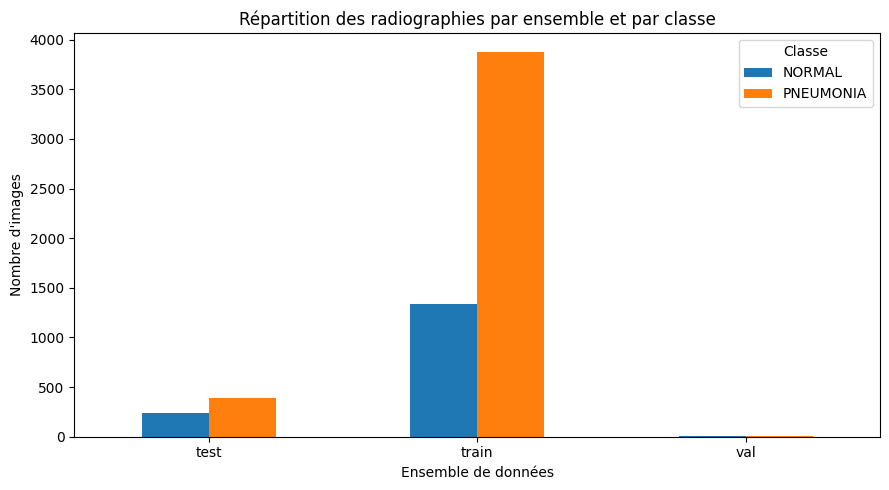

In [8]:
import matplotlib.pyplot as plt

pivot_counts = df_counts.pivot(
    index="Ensemble",
    columns="Classe",
    values="Nombre_images"
).fillna(0)

pivot_counts.plot(kind="bar", figsize=(9, 5))

plt.title("Répartition des radiographies par ensemble et par classe")
plt.xlabel("Ensemble de données")
plt.ylabel("Nombre d'images")
plt.xticks(rotation=0)
plt.legend(title="Classe")
plt.tight_layout()
plt.show()

In [9]:

from PIL import Image, UnidentifiedImageError
from collections import Counter
import pandas as pd

image_info = []

for image_path in valid_images:
    try:
        with Image.open(image_path) as img:
            image_info.append({
                "fichier": image_path.name,
                "classe": image_path.parent.name,
                "ensemble": image_path.parent.parent.name,
                "largeur": img.width,
                "hauteur": img.height,
                "mode": img.mode,
                "format": img.format
            })
    except (UnidentifiedImageError, OSError, ValueError):
        continue

df_images = pd.DataFrame(image_info)

print("Nombre d'images analysées :", len(df_images))
print("\nFormats :")
print(df_images["format"].value_counts())

print("\nModes d'image :")
print(df_images["mode"].value_counts())

print("\nDimensions les plus fréquentes :")
print(
    df_images.groupby(["largeur", "hauteur"])
    .size()
    .sort_values(ascending=False)
    .head(10)
)

display(df_images.head(10))


Nombre d'images analysées : 11712

Formats :
format
JPEG    11712
Name: count, dtype: int64

Modes d'image :
mode
L      11146
RGB      566
Name: count, dtype: int64

Dimensions les plus fréquentes :
largeur  hauteur
1008     704        14
1072     648        14
1080     728        12
992      608        12
         592        12
1216     872        12
1000     704        10
1008     680        10
1160     736        10
1184     792        10
dtype: int64


,fichier,classe,ensemble,largeur,hauteur,mode,format
0,person1180_virus_2010.jpeg,PNEUMONIA,train,1024,712,L,JPEG
1,person1230_virus_2081.jpeg,PNEUMONIA,train,1424,1016,L,JPEG
2,person1513_virus_2632.jpeg,PNEUMONIA,train,1376,1208,L,JPEG
3,person124_virus_238.jpeg,PNEUMONIA,train,1336,1256,L,JPEG
4,person746_virus_1369.jpeg,PNEUMONIA,train,895,516,RGB,JPEG
5,person588_bacteria_2422.jpeg,PNEUMONIA,train,1120,656,L,JPEG
6,person466_virus_960.jpeg,PNEUMONIA,train,1084,717,RGB,JPEG
7,person1590_bacteria_4175.jpeg,PNEUMONIA,train,2000,1896,L,JPEG
8,person399_bacteria_1805.jpeg,PNEUMONIA,train,856,568,L,JPEG
9,person59_bacteria_279.jpeg,PNEUMONIA,train,840,488,L,JPEG


In [10]:
print("Statistiques des dimensions :")
display(df_images[["largeur", "hauteur"]].describe())

print("Images les plus petites :")
display(
    df_images.sort_values(
        by=["largeur", "hauteur"]
    ).head(5)
)

print("Images les plus grandes :")
display(
    df_images.sort_values(
        by=["largeur", "hauteur"],
        ascending=False
    ).head(5)
)

Statistiques des dimensions :


,largeur,hauteur
count,11712.000000,11712.000000
mean,1327.880806,970.689037
std,363.485402,383.375748
min,384.000000,127.000000
25%,1056.000000,688.000000
50%,1281.000000,888.000000
75%,1560.000000,1187.000000
max,2916.000000,2713.000000


Images les plus petites :


,fichier,classe,ensemble,largeur,hauteur,mode,format
2949,person407_virus_811.jpeg,PNEUMONIA,train,384,127,RGB,JPEG
8805,person407_virus_811.jpeg,PNEUMONIA,train,384,127,RGB,JPEG
2625,person1693_bacteria_4485.jpeg,PNEUMONIA,train,399,164,RGB,JPEG
8481,person1693_bacteria_4485.jpeg,PNEUMONIA,train,399,164,RGB,JPEG
3466,person325_virus_660.jpeg,PNEUMONIA,train,400,138,RGB,JPEG


Images les plus grandes :


,fichier,classe,ensemble,largeur,hauteur,mode,format
4622,NORMAL2-IM-1257-0001.jpeg,NORMAL,train,2916,2583,L,JPEG
10478,NORMAL2-IM-1257-0001.jpeg,NORMAL,train,2916,2583,L,JPEG
4589,IM-0521-0001.jpeg,NORMAL,train,2890,2534,L,JPEG
10445,IM-0521-0001.jpeg,NORMAL,train,2890,2534,L,JPEG
4504,IM-0517-0001.jpeg,NORMAL,train,2844,2067,L,JPEG


In [11]:
print("Classes trouvées :")
print(sorted(df_images["classe"].dropna().unique()))

print("\nEnsembles trouvés :")
print(sorted(df_images["ensemble"].dropna().unique()))

print("\nValeurs manquantes :")
print(df_images.isna().sum())

Classes trouvées :
['NORMAL', 'PNEUMONIA']

Ensembles trouvés :
['test', 'train', 'val']

Valeurs manquantes :
fichier     0
classe      0
ensemble    0
largeur     0
hauteur     0
mode        0
format      0
dtype: int64


In [12]:

# Configuration de ChestScan AI

IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 32
SEED = 42

IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)

print("Taille des images :", IMG_SIZE)
print("Batch size :", BATCH_SIZE)
print("Seed :", SEED)


Taille des images : (224, 224)
Batch size : 32
Seed : 42


In [13]:

from pathlib import Path

for split in ["train", "val", "test"]:
    for class_name in ["NORMAL", "PNEUMONIA"]:
        folder = dataset_dir / split / class_name

        if not folder.exists():
            print("Dossier manquant :", folder)
        else:
            print("OK :", folder)


OK : /kaggle/input/chest-xray-pneumonia/chest_xray/train/NORMAL
OK : /kaggle/input/chest-xray-pneumonia/chest_xray/train/PNEUMONIA
OK : /kaggle/input/chest-xray-pneumonia/chest_xray/val/NORMAL
OK : /kaggle/input/chest-xray-pneumonia/chest_xray/val/PNEUMONIA
OK : /kaggle/input/chest-xray-pneumonia/chest_xray/test/NORMAL
OK : /kaggle/input/chest-xray-pneumonia/chest_xray/test/PNEUMONIA


In [14]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

IMG_HEIGHT = 224
IMG_WIDTH = 224
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)
BATCH_SIZE = 32
SEED = 42

print("TensorFlow :", tf.__version__)
print("Taille des images :", IMG_SIZE)
print("Batch size :", BATCH_SIZE)


TensorFlow : 2.21.0
Taille des images : (224, 224)
Batch size : 32


In [15]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    str(dataset_dir / "train"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb",
    class_names=["NORMAL", "PNEUMONIA"],
    seed=SEED,
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    str(dataset_dir / "val"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb",
    class_names=["NORMAL", "PNEUMONIA"],
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    str(dataset_dir / "test"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb",
    class_names=["NORMAL", "PNEUMONIA"],
    shuffle=False
)

print("Ordre des classes :", train_ds.class_names)

Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.
Ordre des classes : ['NORMAL', 'PNEUMONIA']


In [16]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda images, labels: (
        normalization_layer(images), labels
    )
)

val_ds = val_ds.map(
    lambda images, labels: (
        normalization_layer(images), labels
    )
)

test_ds = test_ds.map(
    lambda images, labels: (
        normalization_layer(images), labels
    )
)

In [17]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print("Les trois datasets sont prêts.")

Les trois datasets sont prêts.


In [18]:
for images, labels in train_ds.take(1):
    print("Shape des images :", images.shape)
    print("Shape des labels :", labels.shape)
    print("Valeur minimale des pixels :", float(tf.reduce_min(images)))
    print("Valeur maximale des pixels :", float(tf.reduce_max(images)))
    print("Exemples de labels :", labels[:10].numpy().ravel())

Shape des images : (32, 224, 224, 3)
Shape des labels : (32, 1)
Valeur minimale des pixels : 0.0
Valeur maximale des pixels : 1.0
Exemples de labels : [1. 1. 1. 1. 0. 1. 0. 1. 1. 1.]


In [19]:
# Conserver explicitement l'ordre des classes
class_names = ["NORMAL", "PNEUMONIA"]

print("Classes :", class_names)

Classes : ['NORMAL', 'PNEUMONIA']


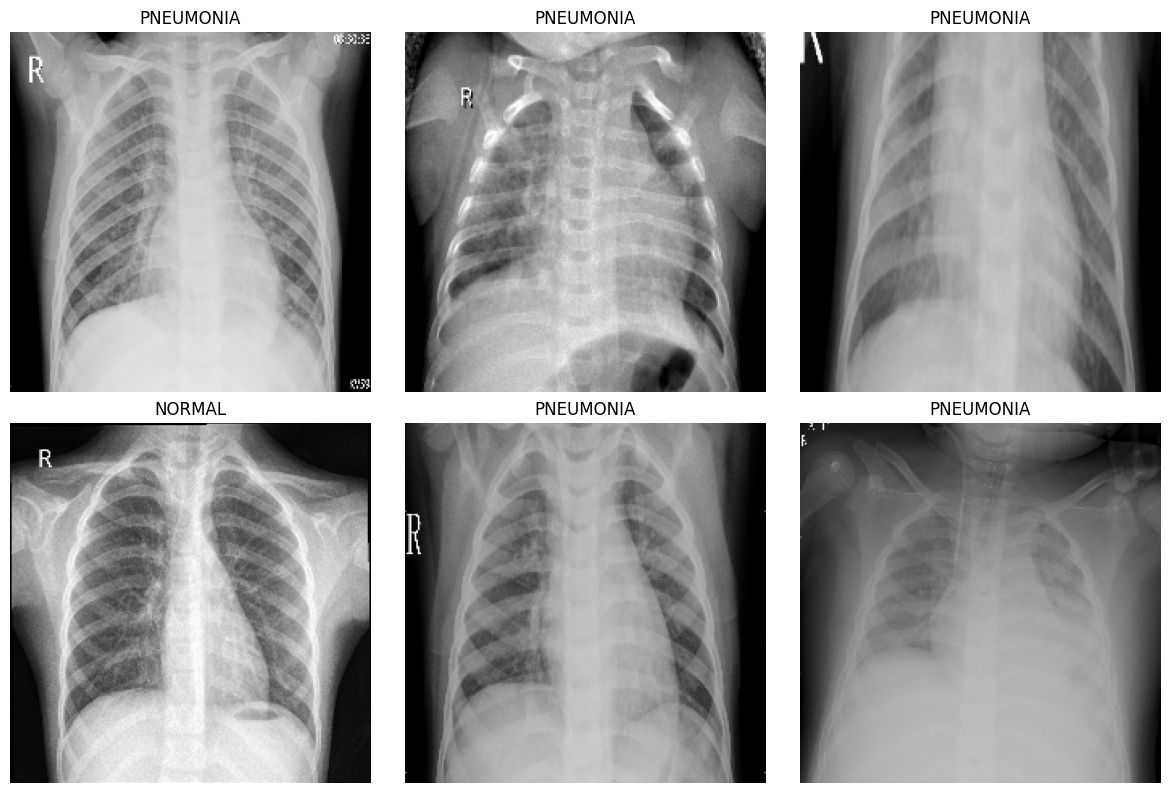

In [20]:
import matplotlib.pyplot as plt

images, labels = next(iter(train_ds))

plt.figure(figsize=(12, 8))

for i in range(min(6, len(images))):
    plt.subplot(2, 3, i + 1)

    plt.imshow(images[i].numpy())

    class_id = int(labels[i].numpy().ravel()[0])
    class_name = class_names[class_id]

    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [21]:

import pandas as pd

splits = {
    "Train": train_ds,
    "Validation": val_ds,
    "Test": test_ds
}

rows = []

for split_name, dataset in splits.items():
    counts = {name: 0 for name in class_names}

    for _, labels in dataset:
        labels = labels.numpy().reshape(-1).astype(int)

        for class_id, class_name in enumerate(class_names):
            counts[class_name] += int((labels == class_id).sum())

    rows.append({
        "Ensemble": split_name,
        "NORMAL": counts["NORMAL"],
        "PNEUMONIA": counts["PNEUMONIA"],
        "Total": sum(counts.values())
    })

df_splits = pd.DataFrame(rows).set_index("Ensemble")
display(df_splits)

print("Total général :", df_splits["Total"].sum())


,NORMAL,PNEUMONIA,Total
Ensemble,,,
Train,1341,3875,5216
Validation,8,8,16
Test,234,390,624


Total général : 5856


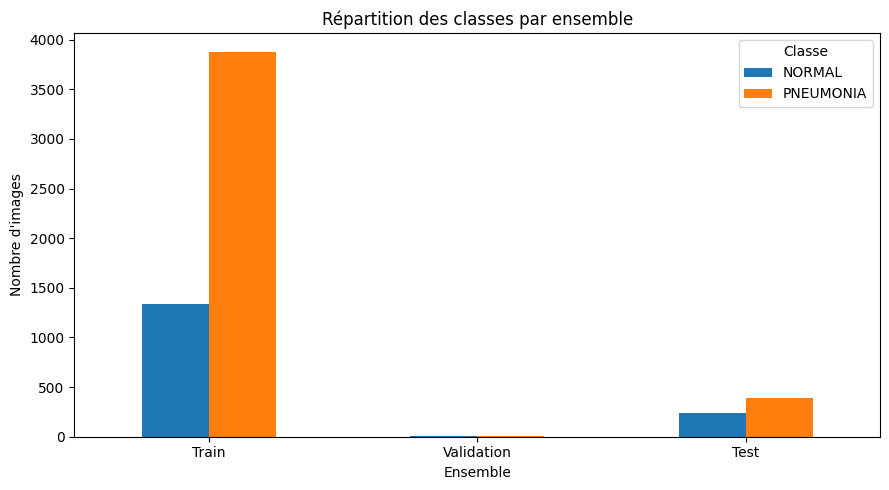

In [22]:
import matplotlib.pyplot as plt

df_splits[["NORMAL", "PNEUMONIA"]].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Répartition des classes par ensemble")
plt.xlabel("Ensemble")
plt.ylabel("Nombre d'images")
plt.xticks(rotation=0)
plt.legend(title="Classe")
plt.tight_layout()
plt.show()

In [23]:

import hashlib
from pathlib import Path

def sha256_file(path):
    digest = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)

    return digest.hexdigest()

extensions = {".jpeg", ".jpg", ".png"}

def get_image_paths(split):
    paths = []

    for class_name in class_names:
        folder = dataset_dir / split / class_name

        for path in folder.rglob("*"):
            if not path.is_file():
                continue
            if path.suffix.lower() not in extensions:
                continue
            if path.name.startswith("._"):
                continue
            if "__MACOSX" in path.parts:
                continue

            paths.append(path)

    return paths

hashes = {}

for split in ["train", "val", "test"]:
    hashes[split] = {
        sha256_file(path)
        for path in get_image_paths(split)
    }

print("Doublons exacts Train / Validation :",
      len(hashes["train"] & hashes["val"]))

print("Doublons exacts Train / Test :",
      len(hashes["train"] & hashes["test"]))

print("Doublons exacts Validation / Test :",
      len(hashes["val"] & hashes["test"]))


Doublons exacts Train / Validation : 0
Doublons exacts Train / Test : 0
Doublons exacts Validation / Test : 0


In [24]:

import tensorflow as tf
from tensorflow.keras import layers, models

IMG_HEIGHT = 224
IMG_WIDTH = 224

model = models.Sequential([
    layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),

    # Extraction des caractéristiques
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),

    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),

    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),

    # Classification
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    # Sortie binaire : 0 = NORMAL, 1 = PNEUMONIA
    layers.Dense(1, activation="sigmoid")
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
for images, labels in train_ds.take(1):
    print("Shape des images :", images.shape)
    print("Shape attendue :", model.input_shape)
    print("Shape des sorties :", model(images[:2]).shape)
    print("Exemples de scores :", model(images[:2]).numpy().ravel())

Shape des images : (32, 224, 224, 3)
Shape attendue : (None, 224, 224, 3)
Shape des sorties : (2, 1)
Exemples de scores : [0.50066817 0.49980518]


In [26]:

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

print("Modèle compilé avec succès.")


Modèle compilé avec succès.


In [27]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath="/content/chestscan_best.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

callbacks = [early_stopping, checkpoint]

In [28]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step - accuracy: 0.7551 - loss: 0.5873 - precision: 0.7878 - recall: 0.9087
Epoch 1: val_loss improved from None to 0.26474, saving model to /content/chestscan_best.keras

Epoch 1: finished saving model to /content/chestscan_best.keras
163/163 ━━━━━━━━━━━━━━━━━━━━ 41s 189ms/step - accuracy: 0.8493 - loss: 0.3496 - precision: 0.8620 - recall: 0.9492 - val_accuracy: 0.8125 - val_loss: 0.2647 - val_precision: 0.8571 - val_recall: 0.7500
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step - accuracy: 0.9453 - loss: 0.1528 - precision: 0.9605 - recall: 0.9647
Epoch 2: val_loss improved from 0.26474 to 0.16530, saving model to /content/chestscan_best.keras

Epoch 2: finished saving model to /content/chestscan_best.keras
163/163 ━━━━━━━━━━━━━━━━━━━━ 31s 190ms/step - accuracy: 0.9475 - loss: 0.1517 - precision: 0.9625 - recall: 0.9670 - val_accuracy: 0.9375 - val_loss: 0.1653 - val_precision: 0.8889 - val_recall: 1.0000
Epoch 3/10
163/163 ━━━━

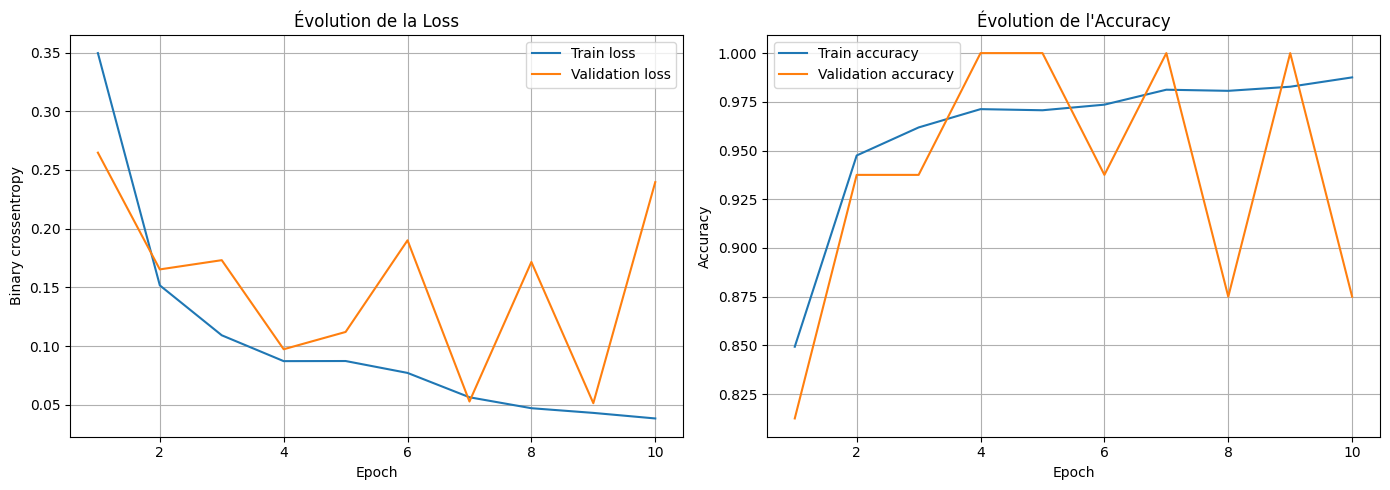

In [29]:

import matplotlib.pyplot as plt

history_dict = history.history
epochs_range = range(1, len(history_dict["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss
axes[0].plot(epochs_range, history_dict["loss"], label="Train loss")
axes[0].plot(epochs_range, history_dict["val_loss"], label="Validation loss")
axes[0].set_title("Évolution de la Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary crossentropy")
axes[0].legend()
axes[0].grid(True)

# Accuracy
axes[1].plot(epochs_range, history_dict["accuracy"], label="Train accuracy")
axes[1].plot(epochs_range, history_dict["val_accuracy"], label="Validation accuracy")
axes[1].set_title("Évolution de l'Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [30]:
import numpy as np

best_epoch = int(np.argmin(history.history["val_loss"])) + 1

print("Nombre d'epochs exécutées :", len(history.history["loss"]))
print("Meilleure epoch selon val_loss :", best_epoch)
print("Meilleure val_loss :", round(float(min(history.history["val_loss"])), 4))
print("Meilleure val_accuracy :", round(float(max(history.history["val_accuracy"])), 4))

Nombre d'epochs exécutées : 10
Meilleure epoch selon val_loss : 9
Meilleure val_loss : 0.0513
Meilleure val_accuracy : 1.0
